# Relaciones bivariadas

Cada fila de `mediciones-pronosticos.csv` combina la observación de una estación con el pronóstico
emitido 6 horas antes para ese mismo momento. En este notebook se estudian las relaciones entre pares de variables:

1. Matriz de correlación entre todas las variables numéricas.
2. Observado vs. pronosticado para cada magnitud.
3. Relaciones físicas entre las variables observadas.
4. Ciclo diario (variables vs. hora local).
5. Error de pronóstico vs. hora y probabilidad de precipitación.
6. Dirección vs. velocidad del viento.
7. Distribución del error de pronóstico y su variación según la hora del día y el valor observado.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

In [2]:
RAW = '../data/raw/'
PROCESSED = '../data/processed/'
OUT = '../data/out/bivariadas/'

# Misma paleta que en analisis_estaciones.ipynb
AZUL, NARANJA = '#2a78d6', '#eb6834'
GRIS_TEXTO, GRIS_GRILLA = '#52514e', '#e4e3df'

# Secuencial (densidad de puntos) y divergente (correlaciones, centrada en 0)
SECUENCIAL = LinearSegmentedColormap.from_list(
    'azules', ['#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
DIVERGENTE = LinearSegmentedColormap.from_list(
    'azul_rojo', ['#184f95', '#6da7ec', '#f0efec', '#ee9190', '#b8302f'])

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRIS_TEXTO, 'axes.labelcolor': GRIS_TEXTO,
    'xtick.color': GRIS_TEXTO, 'ytick.color': GRIS_TEXTO,
    'axes.grid': True, 'grid.color': GRIS_GRILLA, 'grid.linewidth': 0.6,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
})

figuras = {}  # se exportan todas al final

## 1. Carga y limpieza

In [3]:
mp = pd.read_csv(RAW + 'mediciones-pronosticos.csv')
print(f'{mp.shape[0]:,} filas, {mp.shape[1]} columnas - {mp["station_id"].nunique()} estaciones')
mp.dtypes

294,347 filas, 19 columnas - 474 estaciones


station_id                   str
target_hour_utc              str
horizonte_horas            int64
obs_timestamp                str
fcst_target_timestamp        str
fcst_generated_at            str
obs_temp_c                   str
fcst_temp_c              float64
obs_heat_index_c         float64
obs_rh_pct               float64
fcst_rh_pct              float64
obs_wind_direction_d     float64
obs_windspeed_kmh        float64
fcst_windspeed_kmh       float64
obs_dewpoint_c               str
fcst_dewpoint_c              str
fcst_pop_pct             float64
fecha_particion              str
hora_particion             int64
dtype: object

### Números negativos guardados como texto

`obs_temp_c`, `obs_dewpoint_c` y `fcst_dewpoint_c` se leen como texto porque los valores negativos vienen
precedidos por un apóstrofo (`'-5.56`), un escape típico de exportaciones desde planillas. Se quita el apóstrofo y se convierte a número.

In [4]:
VARIABLES = [
    'obs_temp_c', 'fcst_temp_c', 'obs_dewpoint_c', 'fcst_dewpoint_c',
    'obs_rh_pct', 'fcst_rh_pct', 'obs_windspeed_kmh', 'fcst_windspeed_kmh',
    'obs_heat_index_c', 'obs_wind_direction_d', 'fcst_pop_pct',
]

for c in VARIABLES:
    if not pd.api.types.is_numeric_dtype(mp[c]):
        con_apostrofo = mp[c].str.startswith("'").sum()
        print(f'{c}: {con_apostrofo} valores con apóstrofo')
        mp[c] = pd.to_numeric(mp[c].str.lstrip("'"))

for c in ['obs_timestamp', 'fcst_target_timestamp', 'fcst_generated_at']:
    mp[c] = pd.to_datetime(mp[c], utc=True)

obs_temp_c: 36 valores con apóstrofo
obs_dewpoint_c: 81 valores con apóstrofo


fcst_dewpoint_c: 102 valores con apóstrofo


### Valores inválidos

Las temperaturas bajas (hasta ~1 °C) corresponden a estaciones del norte (MI, WI, MN) y el pronóstico las acompaña,
así que son válidas. Sí hay lecturas imposibles, por ejemplo -42 °C con un pronóstico de 20 °C o un viento de 156 km/h repetido
en varias filas. Se marcan como faltantes:

- temperatura o punto de rocío observados que difieren **más de 15 °C** del pronóstico,
- viento observado **mayor a 120 km/h** (en septiembre no hubo eventos de ese tipo en la región).

In [5]:
invalidos = {
    'obs_temp_c': (mp['obs_temp_c'] - mp['fcst_temp_c']).abs() > 15,
    'obs_dewpoint_c': (mp['obs_dewpoint_c'] - mp['fcst_dewpoint_c']).abs() > 15,
    'obs_windspeed_kmh': mp['obs_windspeed_kmh'] > 120,
}
for c, mascara in invalidos.items():
    print(f'{c}: {mascara.sum()} valores descartados')
    mp.loc[mascara, c] = np.nan

# La sensación térmica depende de la temperatura: si esta se descartó, también aquella
mp.loc[invalidos['obs_temp_c'], 'obs_heat_index_c'] = np.nan

obs_temp_c: 44 valores descartados
obs_dewpoint_c: 43 valores descartados
obs_windspeed_kmh: 6 valores descartados


### Hora local

La hora UTC mezcla el día y la noche entre estaciones de distintos husos. Para estudiar el ciclo diario se convierte
cada observación a la hora local de su estación (`timeZone` de los metadatos).

In [6]:
estaciones = gpd.read_file(PROCESSED + 'estaciones_central.geojson')
mp = mp.merge(estaciones[['id', 'estado', 'timeZone']], left_on='station_id', right_on='id', how='left').drop(columns='id')
print(f"Filas sin zona horaria: {mp['timeZone'].isna().sum()}")

mp['hora_local'] = np.nan
for tz, idx in mp.groupby('timeZone').groups.items():
    mp.loc[idx, 'hora_local'] = mp.loc[idx, 'fcst_target_timestamp'].dt.tz_convert(tz).dt.hour
mp['hora_local'] = mp['hora_local'].astype(int)

mp['timeZone'].value_counts()

Filas sin zona horaria: 0


timeZone
America/Chicago                 270253
America/Detroit                  14280
America/Indiana/Indianapolis      7345
America/Denver                    2469
Name: count, dtype: int64

### Datos faltantes en las observaciones

Los pronósticos están completos, pero en el dataset original más de un tercio de las filas (34,7 %) no tiene ninguna
observación y cada variable observada falta en entre el 36 % y el 46 % de las filas. Como se detalla más abajo, la mayor parte
de esos faltantes proviene de estaciones que no miden variables meteorológicas y que se excluyen del análisis.
Aun después de excluirlas, cada gráfico usa **todos los pares completos** de las dos variables que compara,
por lo que el `n` cambia de un panel a otro.

In [7]:
(mp[VARIABLES].notna().mean().mul(100).round(1)
 .rename('% de filas con dato').to_frame()
 .sort_values('% de filas con dato'))

,% de filas con dato
obs_heat_index_c,54.2
obs_rh_pct,60.7
obs_dewpoint_c,61.5
obs_wind_direction_d,62.8
obs_windspeed_kmh,63.2
obs_temp_c,63.5
fcst_dewpoint_c,100.0
fcst_temp_c,100.0
fcst_windspeed_kmh,100.0
fcst_rh_pct,100.0


### Estaciones que no miden y origen del resto de los faltantes

Los faltantes no están repartidos al azar: la mayoría se concentra en estaciones que **no tienen sensores meteorológicos**.
La metadata incluye muchas estaciones hidrológicas (pluviómetros y medidores de nivel de ríos de redes como HADS, HCFCD o AUSTIN).
api.weather.gov les publica observaciones cada hora, pero con todas las variables meteorológicas en `null`, y el ETL las guardó
igual como filas vacías.

`ETL/clasificar_estaciones.py` mide la cobertura de cada estación (fracción de horas con dato) en temperatura, punto de rocío,
HR y viento, y clasifica las 500 estaciones de la metadata:

| Categoría | Estaciones | Criterio |
|---|---|---|
| `ok` | 256 | reporta todas las variables, con al menos una por encima del 90 % de las horas |
| `parcial_por_variable` | 20 | le falta algún sensor (8 sin viento, 7 sin humedad ni punto de rocío, 4 sólo miden viento) |
| `intermitente` | 69 | mide, pero ninguna variable llega al 90 % de las horas (mediana ≈ 40 %) |
| `sin_meteo` | 129 | ninguna variable supera el 1 % de las horas |
| `sin_registros` | 26 | no tiene filas en el dataset |

Las 129 estaciones `sin_meteo` son 71 de HADS y 58 de redes de MesoWest (30 de AUSTIN, 13 de MIDCoEMO, 11 de HCFCD y 4 de ARDOT).
La consulta a la API (últimas 50 observaciones de cada una) confirma que 126 de ellas no traen ningún dato meteorológico.
Estas estaciones aportan 77.050 filas (26 % del total) con un solo valor observado, así que **se excluyen**. Con eso las filas sin
ninguna observación pasan del 34,7 % al 11,6 %. Las 26 `sin_registros` ya no estaban en `mp`.

El resto de los faltantes tiene otros orígenes y **no se excluye**, porque esas estaciones sí aportan datos válidos:

- **Estaciones intermitentes**: 65 de las 69 son de APRSWXNET (estaciones de aficionados de la red CWOP). Concentran 23.340 de las
  25.106 filas vacías que quedan (el 58 % de sus filas no tiene dato). El ETL toma la observación más reciente de cada hora
  (`/observations/latest`) y en estas estaciones suele caer en un registro vacío.
- **Sensores ausentes**: las 20 estaciones `parcial_por_variable` nunca reportan una o más variables.
- **Huecos puntuales**: en las estaciones `ok` menos del 1 % de las filas está vacía.
- **Valores descartados**: las lecturas imposibles marcadas como faltantes en la limpieza (44 temperaturas, 43 puntos de rocío y 6 vientos).
- **Sensación térmica**: no es un faltante real. La API sólo la informa con calor (en el dataset, a partir de ≈ 21 °C), por eso
  es la variable con menos datos aunque la temperatura esté presente.

In [8]:
excluidas = pd.read_csv(PROCESSED + 'estaciones_sin_meteo.csv')
filas_antes, estaciones_antes = len(mp), mp['station_id'].nunique()

mp = mp[~mp['station_id'].isin(excluidas['station_id'])].reset_index(drop=True)
print(f'Estaciones: {estaciones_antes} -> {mp["station_id"].nunique()} - '
      f'filas: {filas_antes:,} -> {len(mp):,} ({filas_antes - len(mp):,} excluidas)')

(mp[VARIABLES].notna().mean().mul(100).round(1)
 .rename('% de filas con dato').to_frame()
 .sort_values('% de filas con dato'))

Estaciones: 474 -> 345 - filas: 294,347 -> 217,297 (77,050 excluidas)


,% de filas con dato
obs_heat_index_c,73.4
obs_rh_pct,82.2
obs_dewpoint_c,83.2
obs_wind_direction_d,85.1
obs_windspeed_kmh,85.6
obs_temp_c,85.9
fcst_dewpoint_c,100.0
fcst_temp_c,100.0
fcst_windspeed_kmh,100.0
fcst_rh_pct,100.0


## 2. Matriz de correlación

Se calculan Pearson (relación lineal) y Spearman (relación monótona, robusta a valores extremos).
La dirección del viento se excluye porque es una variable circular (0° y 360° son lo mismo).

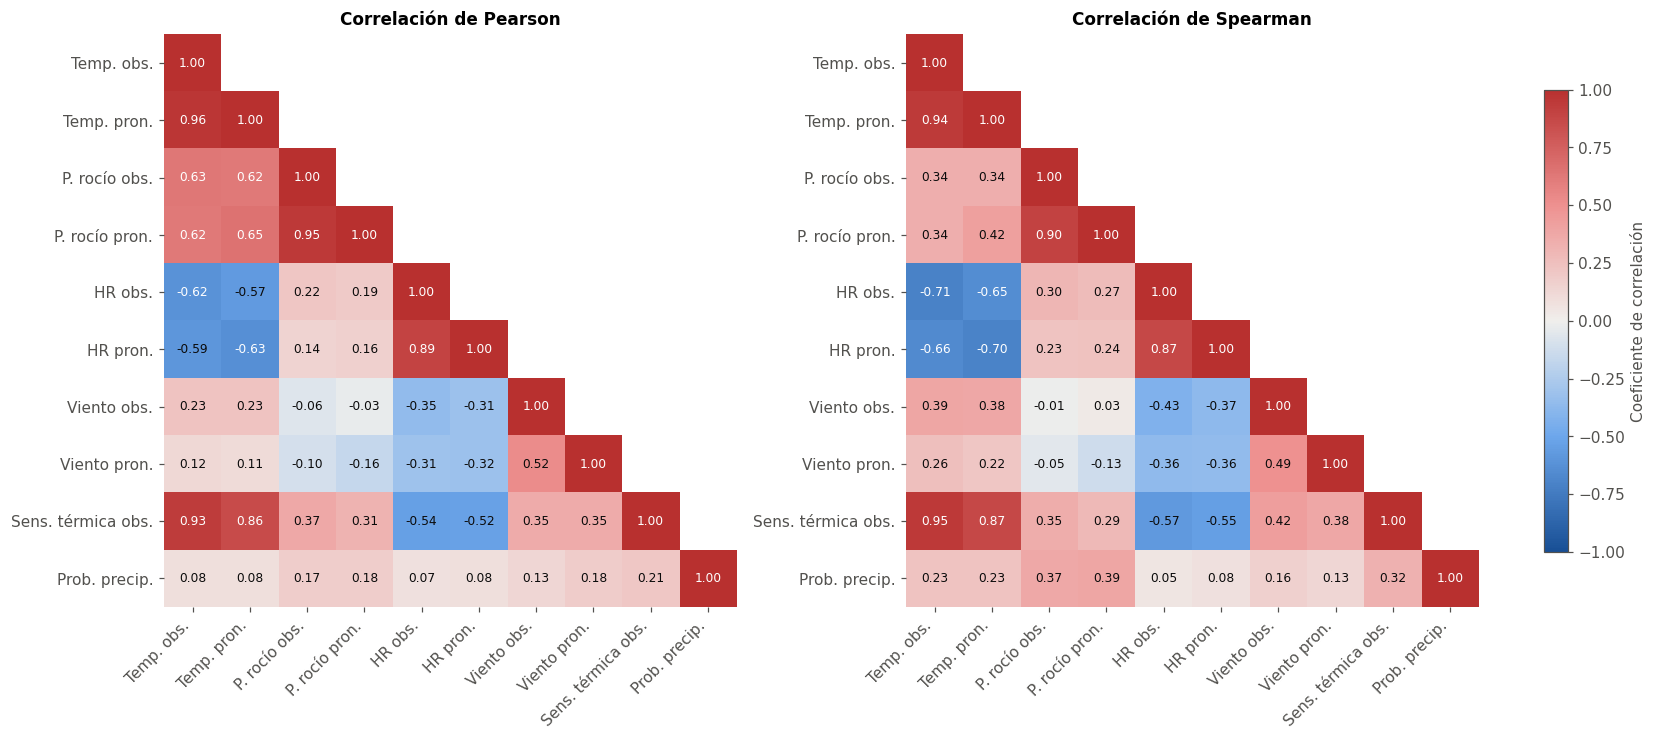

In [9]:
ETIQUETAS = {
    'obs_temp_c': 'Temp. obs.', 'fcst_temp_c': 'Temp. pron.',
    'obs_dewpoint_c': 'P. rocío obs.', 'fcst_dewpoint_c': 'P. rocío pron.',
    'obs_rh_pct': 'HR obs.', 'fcst_rh_pct': 'HR pron.',
    'obs_windspeed_kmh': 'Viento obs.', 'fcst_windspeed_kmh': 'Viento pron.',
    'obs_heat_index_c': 'Sens. térmica obs.', 'fcst_pop_pct': 'Prob. precip.',
}
vars_corr = list(ETIQUETAS)
datos_corr = mp[vars_corr].rename(columns=ETIQUETAS)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), constrained_layout=True)
for ax, metodo, titulo in zip(axes, ['pearson', 'spearman'], ['Pearson', 'Spearman']):
    corr = datos_corr.corr(method=metodo)
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
    im = ax.imshow(corr.mask(mascara), cmap=DIVERGENTE, vmin=-1, vmax=1)
    for i in range(len(corr)):
        for j in range(i + 1):
            v = corr.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(v) > 0.6 else '#0b0b0b')
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(corr)), corr.index)
    ax.grid(False)
    ax.spines[:].set_visible(False)
    ax.set_title(f'Correlación de {titulo}')
fig.colorbar(im, ax=axes, shrink=0.8, label='Coeficiente de correlación')
figuras['01_matriz_correlacion'] = fig
plt.show()

## 3. Observado vs. pronosticado

Cada panel compara la observación con el pronóstico emitido 6 h antes. Con ~190 mil puntos un scatter se satura,
así que se usa un **hexbin** con la cantidad de registros por celda en escala logarítmica. La línea punteada es `y = x`
(pronóstico perfecto).

In [10]:
def hexbin_par(ax, datos, x, y, identidad=False, gridsize=60, texto_abajo=False):
    """Hexbin de densidad para un par de variables, con r de Pearson y rho de Spearman."""
    d = datos[[x, y]].dropna()
    hb = ax.hexbin(d[x], d[y], gridsize=gridsize, bins='log', mincnt=1,
                   cmap=SECUENCIAL, linewidths=0)
    if identidad:
        lims = [d[x].min(), d[x].max()]
        ax.plot(lims, lims, color=NARANJA, lw=1.5, ls='--', label='y = x')
        ax.legend(loc='lower right', frameon=False)
    r = d[x].corr(d[y])
    rho = d[x].corr(d[y], method='spearman')
    ax.text(0.03, 0.03 if texto_abajo else 0.97, f'r = {r:.2f}   ρ = {rho:.2f}\nn = {len(d):,}',
            transform=ax.transAxes, va='bottom' if texto_abajo else 'top', fontsize=9, color=GRIS_TEXTO,
            bbox=dict(fc='white', ec='none', alpha=0.85))
    ax.grid(False)
    return hb


def escala_comun(hexbins):
    """Misma escala de color en todos los paneles, para que la barra de color valga para todos."""
    vmax = max(hb.get_array().max() for hb in hexbins)
    for hb in hexbins:
        hb.set_norm(LogNorm(vmin=1, vmax=vmax))
    return hexbins[-1]

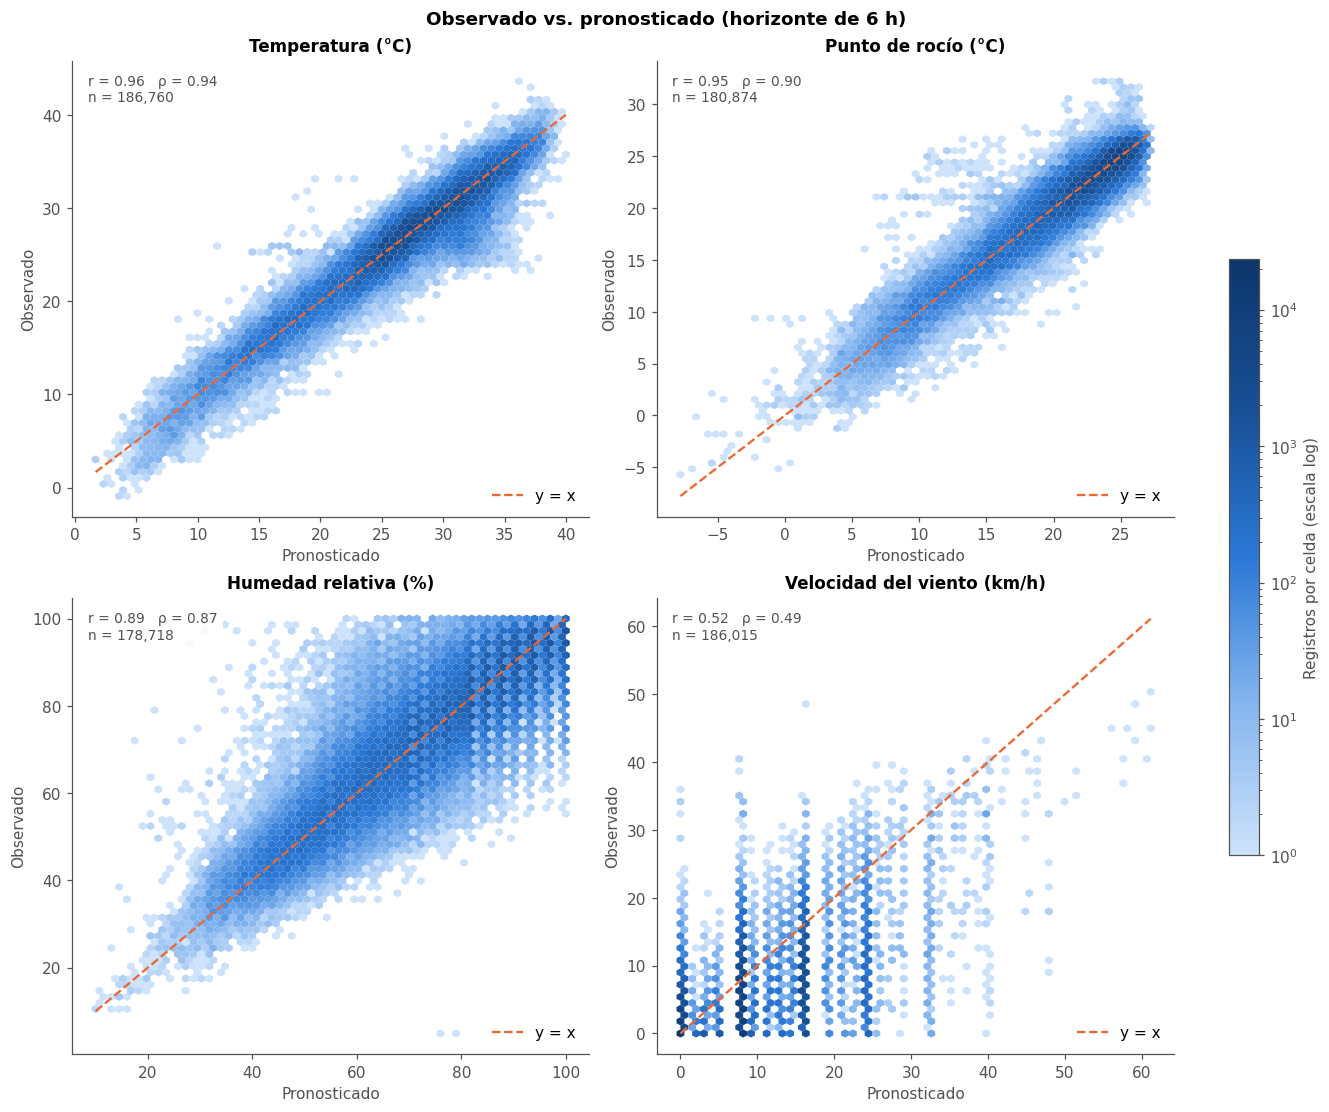

In [11]:
PARES_OBS_PRON = [
    ('Temperatura (°C)', 'fcst_temp_c', 'obs_temp_c'),
    ('Punto de rocío (°C)', 'fcst_dewpoint_c', 'obs_dewpoint_c'),
    ('Humedad relativa (%)', 'fcst_rh_pct', 'obs_rh_pct'),
    ('Velocidad del viento (km/h)', 'fcst_windspeed_kmh', 'obs_windspeed_kmh'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
hexbins = []
for ax, (nombre, pron, obs) in zip(axes.flat, PARES_OBS_PRON):
    hexbins.append(hexbin_par(ax, mp, pron, obs, identidad=True))
    ax.set(title=nombre, xlabel='Pronosticado', ylabel='Observado')
fig.colorbar(escala_comun(hexbins), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('Observado vs. pronosticado (horizonte de 6 h)', fontweight='bold')
figuras['02_observado_vs_pronosticado'] = fig
plt.show()

Resumen numérico del acuerdo entre observación y pronóstico (error = observado − pronosticado):

In [12]:
filas = []
for nombre, pron, obs in PARES_OBS_PRON:
    d = mp[[pron, obs]].dropna()
    error = d[obs] - d[pron]
    filas.append({
        'Variable': nombre, 'n': len(d),
        'Pearson r': d[obs].corr(d[pron]),
        'Sesgo (media del error)': error.mean(),
        'MAE': error.abs().mean(),
        'RMSE': np.sqrt((error ** 2).mean()),
    })
tabla_obs_pron = pd.DataFrame(filas).set_index('Variable').round(2)
tabla_obs_pron

,n,Pearson r,Sesgo (media del error),MAE,RMSE
Variable,,,,,
Temperatura (°C),186760,0.96,-0.07,1.08,1.48
Punto de rocío (°C),180874,0.95,0.01,0.93,1.29
Humedad relativa (%),178718,0.89,0.23,5.71,7.66
Velocidad del viento (km/h),186015,0.52,-2.93,4.80,6.48


### ¿Por qué el viento se ajusta peor?

No es un problema de unidades. El pronóstico llega de la API como texto en mph enteras (`"10 mph"`) y el ETL lo pasa a km/h
(`ETL/merge_data.py`), mientras que la observación ya viene en km/h. Los valores observados más frecuentes (1,62; 3,24; 4,82; 6,44 km/h, ...)
son pasos de 1 mph convertidos, igual en todas las redes, así que ninguna reporta en otra unidad (multiplicar por 3,6, como si fueran m/s,
empeora el ajuste en todas).

El peor ajuste se explica por:

- **Emplazamiento del sensor**: el pronóstico corresponde al viento a 10 m de altura en terreno abierto, pero muchas estaciones están más
  bajas o protegidas por edificios y árboles, y miden menos viento. Por eso el sesgo es negativo en todas las redes.
- **Cuantización**: el pronóstico toma muy pocos valores (casi siempre 0, 5 o 10 mph), lo que baja la correlación.
- **Calmas**: muchas estaciones reportan 0 km/h mientras el pronóstico indica viento leve.
- **Representatividad**: la observación es un promedio de pocos minutos en un punto y el pronóstico un valor horario para una celda de
  ≈ 2,5 km. El viento varía mucho más que la temperatura en el tiempo y en el espacio.

La tabla compara las redes con más de 3.000 pares. Las estaciones RAWS (en campo abierto y a altura estándar) se ajustan mucho mejor que
las de aficionados de APRSWXNET.

In [13]:
redes = pd.read_csv(PROCESSED + 'cobertura_estaciones.csv', usecols=['station_id', 'provider', 'subProvider'])
redes['red'] = redes['subProvider'].fillna(redes['provider'])
viento_red = (mp[['station_id', 'fcst_windspeed_kmh', 'obs_windspeed_kmh']].dropna()
              .merge(redes[['station_id', 'red']], on='station_id'))


def metricas_viento(d):
    error = d['obs_windspeed_kmh'] - d['fcst_windspeed_kmh']
    return pd.Series({
        'n': len(d),
        'Pearson r': d['obs_windspeed_kmh'].corr(d['fcst_windspeed_kmh']),
        'Sesgo (media del error)': error.mean(),
        'MAE': error.abs().mean(),
        '% calmas obs.': 100 * d['obs_windspeed_kmh'].eq(0).mean(),
    })


tabla_viento_red = (viento_red.groupby('red')[['fcst_windspeed_kmh', 'obs_windspeed_kmh']].apply(metricas_viento)
                    .query('n > 3000').sort_values('Pearson r', ascending=False))
tabla_viento_red.loc['Todas'] = metricas_viento(viento_red)
tabla_viento_red.loc['Todas sin APRSWXNET'] = metricas_viento(viento_red[viento_red['red'] != 'APRSWXNET'])
tabla_viento_red['n'] = tabla_viento_red['n'].astype(int)
tabla_viento_red.round(2)

,n,Pearson r,Sesgo (media del error),MAE,% calmas obs.
red,,,,,
RAWS,7733,0.80,-2.52,4.43,19.13
CENTERPOINT,96676,0.58,-2.71,4.38,12.07
HADS,3271,0.50,-3.37,5.35,1.74
WEATHERSTEM,37156,0.45,-3.18,5.02,28.58
ARDOT,17926,0.39,-0.09,4.00,13.41
APRSWXNET,17625,0.35,-7.19,7.77,47.12
Todas,186015,0.52,-2.93,4.80,18.76
Todas sin APRSWXNET,168390,0.56,-2.48,4.49,15.79


## 4. Relaciones entre variables observadas

Relaciones físicas esperables entre las mediciones:

- **Temperatura vs. humedad relativa**: con la misma cantidad de vapor, el aire más caliente tiene menor HR.
- **Temperatura vs. punto de rocío**: el punto de rocío nunca supera a la temperatura (cota superior `y = x`).
- **Temperatura vs. sensación térmica**: coinciden con calor seco y se separan cuando la humedad es alta.
- **Humedad relativa vs. viento**: el viento mezcla el aire y suele coincidir con horas de menor HR.

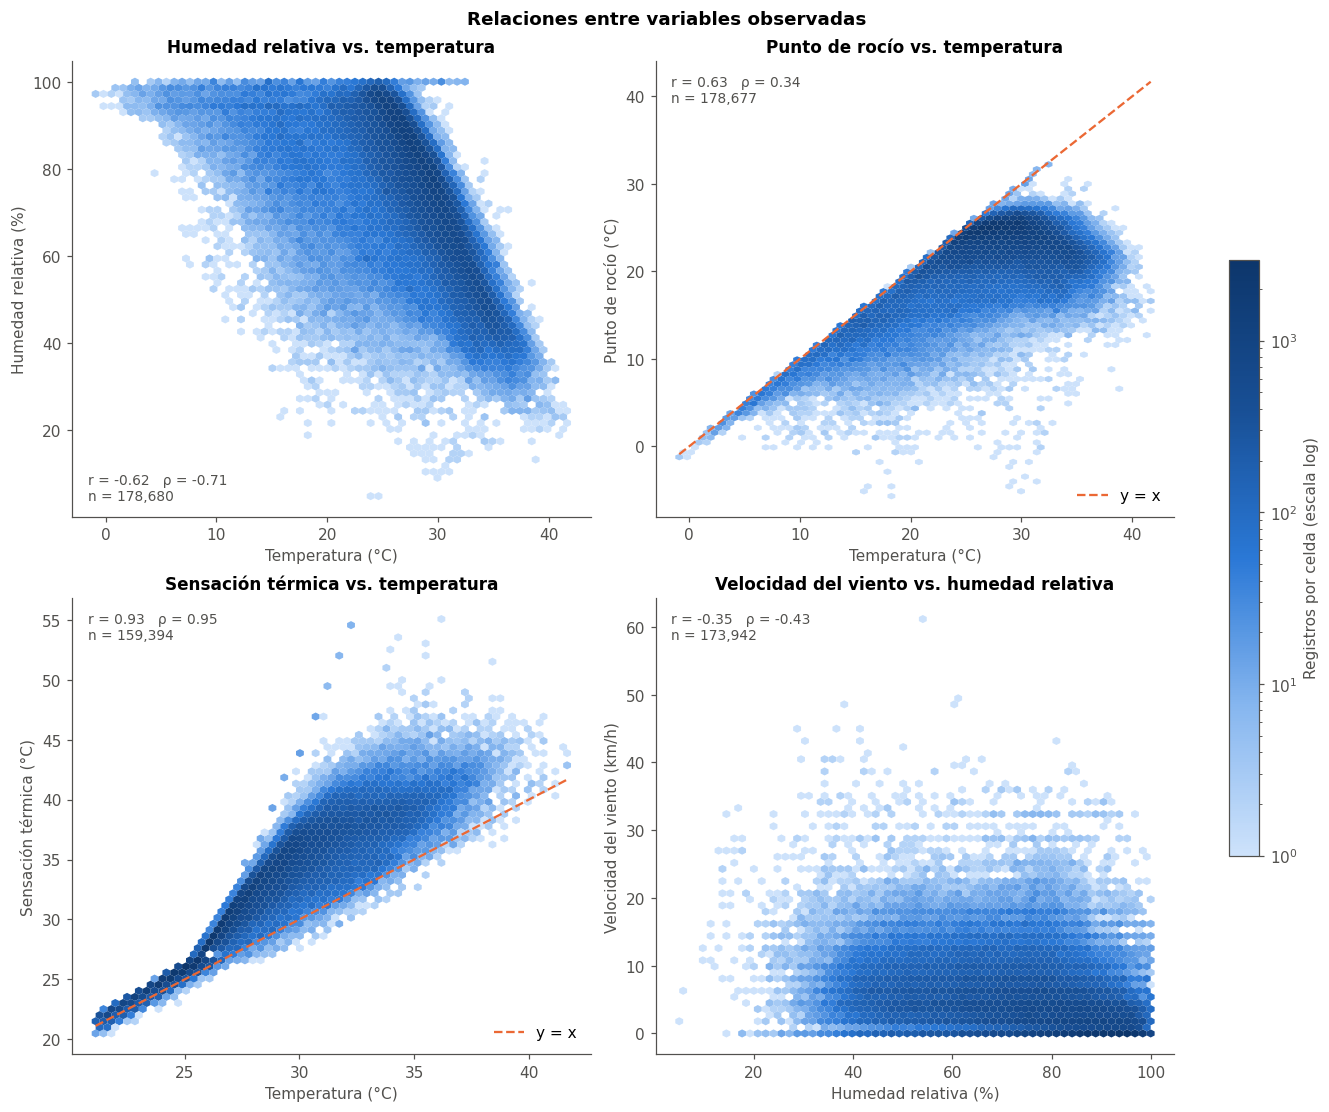

In [14]:
PARES_OBS = [
    ('obs_temp_c', 'obs_rh_pct', 'Temperatura (°C)', 'Humedad relativa (%)', False, True),
    ('obs_temp_c', 'obs_dewpoint_c', 'Temperatura (°C)', 'Punto de rocío (°C)', True, False),
    ('obs_temp_c', 'obs_heat_index_c', 'Temperatura (°C)', 'Sensación térmica (°C)', True, False),
    ('obs_rh_pct', 'obs_windspeed_kmh', 'Humedad relativa (%)', 'Velocidad del viento (km/h)', False, False),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
hexbins = []
for ax, (x, y, etiqueta_x, etiqueta_y, identidad, texto_abajo) in zip(axes.flat, PARES_OBS):
    hexbins.append(hexbin_par(ax, mp, x, y, identidad=identidad, texto_abajo=texto_abajo))
    ax.set(title=f'{etiqueta_y.split(" (")[0]} vs. {etiqueta_x.split(" (")[0].lower()}',
           xlabel=etiqueta_x, ylabel=etiqueta_y)
fig.colorbar(escala_comun(hexbins), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('Relaciones entre variables observadas', fontweight='bold')
figuras['03_relaciones_observadas'] = fig
plt.show()

## 5. Ciclo diario

Cada variable se grafica contra la hora local. La línea es la media y la banda el rango intercuartílico (P25–P75)
de todas las estaciones y días. Se usa la media y no la mediana porque el pronóstico de viento toma pocos valores
(8,05 km/h = 5 mph, 16,09 km/h = 10 mph, ...) y su mediana salta de un escalón a otro. Se usa un panel por variable para no mezclar escalas en un mismo eje.

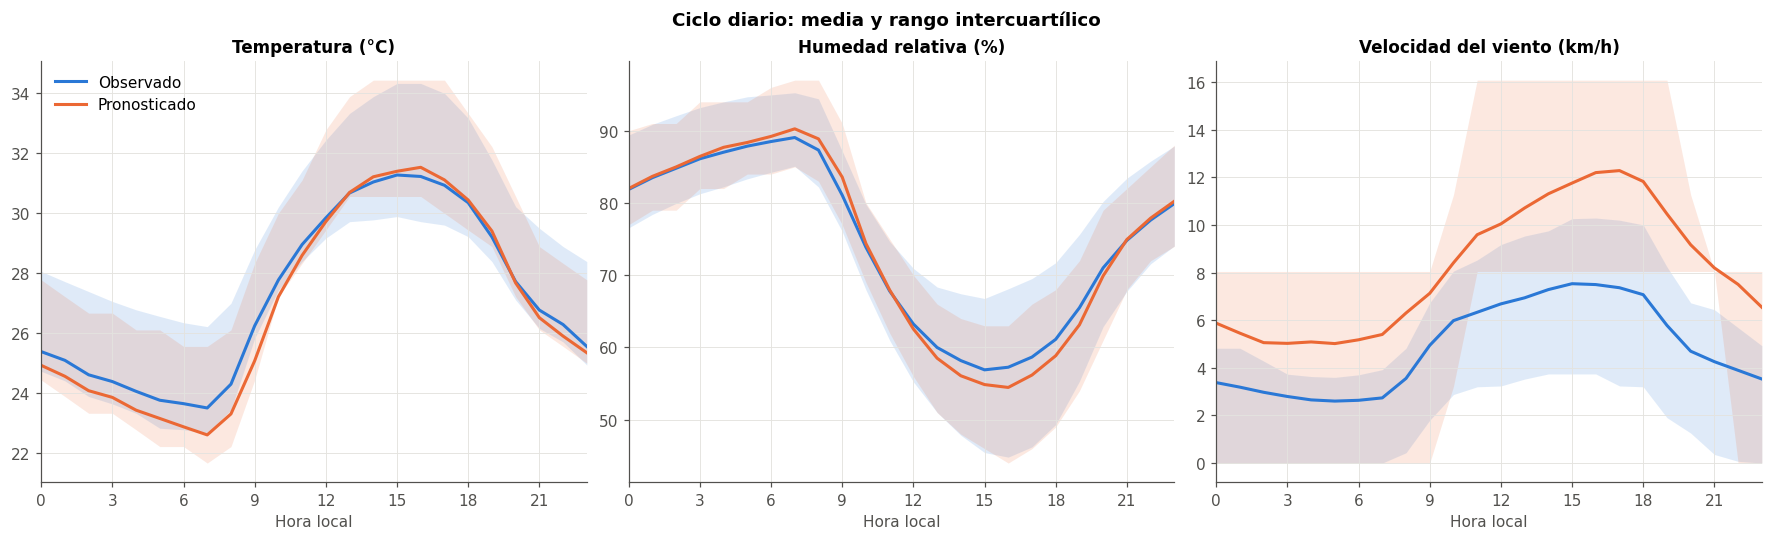

In [15]:
def banda_por_hora(ax, datos, variable, color, etiqueta):
    """Media y rango intercuartílico de una variable por hora local."""
    g = datos.groupby('hora_local')[variable]
    q = g.quantile([0.25, 0.75]).unstack()
    ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.15, linewidth=0)
    ax.plot(q.index, g.mean(), color=color, lw=2, label=etiqueta)

CICLO = [
    ('Temperatura (°C)', 'obs_temp_c', 'fcst_temp_c'),
    ('Humedad relativa (%)', 'obs_rh_pct', 'fcst_rh_pct'),
    ('Velocidad del viento (km/h)', 'obs_windspeed_kmh', 'fcst_windspeed_kmh'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, (nombre, obs, pron) in zip(axes, CICLO):
    banda_por_hora(ax, mp, obs, AZUL, 'Observado')
    banda_por_hora(ax, mp, pron, NARANJA, 'Pronosticado')
    ax.set(title=nombre, xlabel='Hora local', xticks=range(0, 24, 3), xlim=(0, 23))
axes[0].legend(frameon=False)
fig.suptitle('Ciclo diario: media y rango intercuartílico', fontweight='bold')
figuras['04_ciclo_diario'] = fig
plt.show()

## 6. Error del pronóstico de temperatura

Se analiza el error `observado − pronosticado` de la temperatura frente a dos variables:

- la **hora local**, para ver si el modelo falla sistemáticamente en algún momento del día;
- la **probabilidad de precipitación** pronosticada, ya que la lluvia y la nubosidad son difíciles de anticipar
  y enfrían el aire.

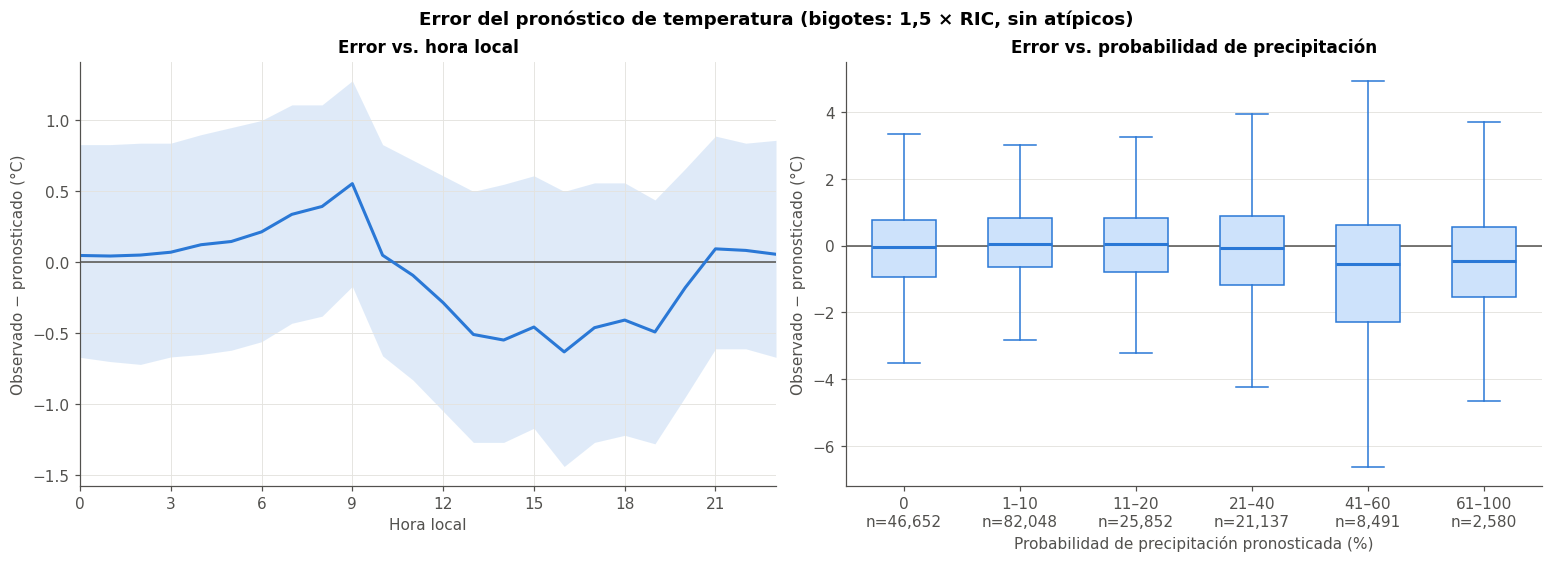

In [16]:
mp['error_temp_c'] = mp['obs_temp_c'] - mp['fcst_temp_c']

cortes_pop = [-0.1, 0, 10, 20, 40, 60, 100]
etiquetas_pop = ['0', '1–10', '11–20', '21–40', '41–60', '61–100']
mp['pop_rango'] = pd.cut(mp['fcst_pop_pct'], cortes_pop, labels=etiquetas_pop)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

ax1.axhline(0, color=GRIS_TEXTO, lw=1)
banda_por_hora(ax1, mp, 'error_temp_c', AZUL, 'Media')
ax1.set(title='Error vs. hora local', xlabel='Hora local', ylabel='Observado − pronosticado (°C)',
        xticks=range(0, 24, 3), xlim=(0, 23))

d = mp.dropna(subset=['error_temp_c'])
grupos = [g['error_temp_c'].values for _, g in d.groupby('pop_rango', observed=False)]
ax2.axhline(0, color=GRIS_TEXTO, lw=1)
etiquetas_n = [f'{e}\nn={len(g):,}' for e, g in zip(etiquetas_pop, grupos)]
ax2.boxplot(grupos, tick_labels=etiquetas_n, showfliers=False, widths=0.55, patch_artist=True,
            boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
            whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax2.set(title='Error vs. probabilidad de precipitación', xlabel='Probabilidad de precipitación pronosticada (%)',
        ylabel='Observado − pronosticado (°C)')
ax2.grid(axis='x', visible=False)

fig.suptitle('Error del pronóstico de temperatura (bigotes: 1,5 × RIC, sin atípicos)', fontweight='bold')
figuras['05_error_temperatura'] = fig
plt.show()

In [17]:
(mp.groupby('pop_rango', observed=False)['error_temp_c']
 .agg(n='count', sesgo='mean', mediana='median', MAE=lambda e: e.abs().mean())
 .round(2))

,n,sesgo,mediana,MAE
pop_rango,,,,
0,46652,-0.09,-0.05,1.06
1–10,82048,0.09,0.06,0.94
11–20,25852,-0.05,0.05,1.07
21–40,21137,-0.28,-0.06,1.36
41–60,8491,-0.96,-0.56,1.86
61–100,2580,-0.53,-0.45,1.37


## 7. Dirección vs. velocidad del viento

Rosa de los vientos: cada barra es un sector de 22,5° según la dirección **desde la que sopla** el viento (0° = norte),
su largo es el porcentaje de observaciones en ese sector y los tramos apilados indican la velocidad (más oscuro = más rápido).
Se excluyen las calmas (velocidad 0), que se reportan con dirección 0°.

Calmas excluidas: 34,417 (18.6% de las observaciones de viento)


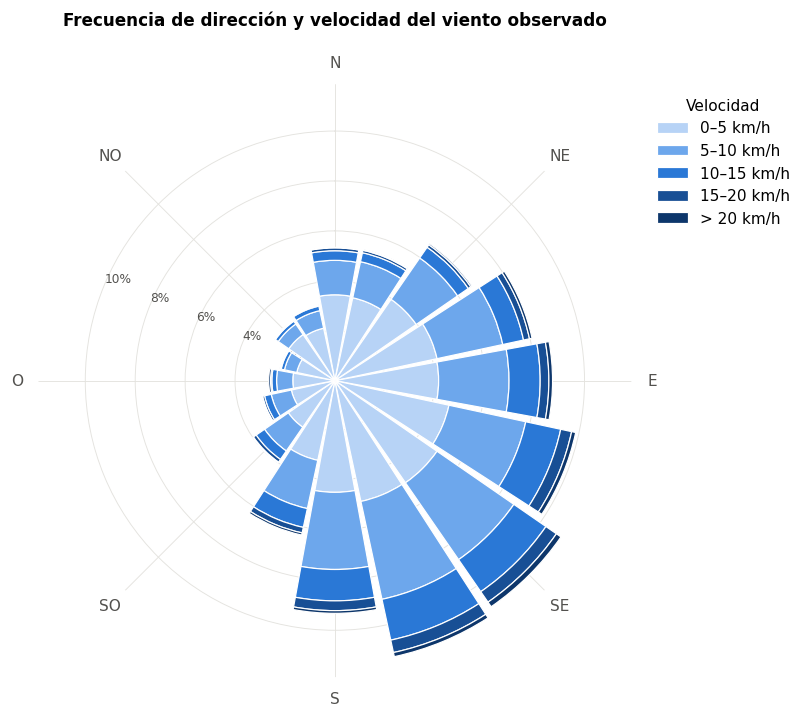

In [18]:
viento = mp[['obs_wind_direction_d', 'obs_windspeed_kmh']].dropna()
calmas = viento['obs_windspeed_kmh'].eq(0)
print(f'Calmas excluidas: {calmas.sum():,} ({calmas.mean():.1%} de las observaciones de viento)')
viento = viento[~calmas]

SECTOR = 22.5
cortes_vel = [0, 5, 10, 15, 20, np.inf]
etiquetas_vel = ['0–5', '5–10', '10–15', '15–20', '> 20']
colores_vel = ['#b7d3f6', '#6da7ec', '#2a78d6', '#184f95', '#0d366b']

sector = ((viento['obs_wind_direction_d'] + SECTOR / 2) % 360 // SECTOR).astype(int)
rango_vel = pd.cut(viento['obs_windspeed_kmh'], cortes_vel, labels=etiquetas_vel)
frecuencia = (pd.crosstab(sector, rango_vel, normalize=True) * 100).reindex(range(16), fill_value=0)

angulos = np.deg2rad(frecuencia.index * SECTOR)
fig = plt.figure(figsize=(7.5, 7))
ax = fig.add_subplot(projection='polar')
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
base = np.zeros(len(frecuencia))
for etiqueta, color in zip(etiquetas_vel, colores_vel):
    ax.bar(angulos, frecuencia[etiqueta], width=np.deg2rad(SECTOR) * 0.92, bottom=base,
           color=color, edgecolor='white', linewidth=0.8, label=f'{etiqueta} km/h')
    base += frecuencia[etiqueta].values
ax.set_xticks(np.deg2rad(range(0, 360, 45)), ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO'])
ax.set_rlabel_position(292.5)  # sector con poco viento, las etiquetas no quedan tapadas
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.tick_params(axis='y', labelsize=8, colors=GRIS_TEXTO)
ax.grid(color=GRIS_GRILLA)
ax.set_axisbelow(True)
ax.spines['polar'].set_visible(False)
ax.legend(title='Velocidad', loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
ax.set_title('Frecuencia de dirección y velocidad del viento observado', pad=20)
figuras['06_direccion_velocidad_viento'] = fig
plt.show()

In [19]:
sectores = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
viento['sector'] = pd.Categorical(
    np.array(sectores)[(((viento['obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)], sectores)
(viento.groupby('sector', observed=False)['obs_windspeed_kmh']
 .agg(frecuencia_pct=lambda s: 100 * len(s) / len(viento), mediana_kmh='median', p90_kmh=lambda s: s.quantile(0.9))
 .round(1))

,frecuencia_pct,mediana_kmh,p90_kmh
sector,,,
N,9.5,3.7,9.8
NE,13.5,4.4,10.5
E,17.4,5.3,12.9
SE,22.2,5.6,13.2
S,18.2,5.3,12.9
SO,8.4,4.8,11.7
O,5.2,3.8,10.8
NO,5.6,3.2,8.7


### Distribución geográfica del viento

La rosa junta todas las observaciones, pero el 70 % viene de la franja del Golfo (Texas sola aporta el 64 %), así que describe
sobre todo el sur de la región. Para ver cómo cambia el viento en el territorio y cómo se relaciona con el error del pronóstico,
se dibuja una flecha por estación (las que tienen al menos 100 observaciones de viento):

- **Dirección**: promedio vectorial de las observaciones sin calmas. La flecha apunta **hacia donde va** el viento (la rosa usa la
  dirección desde la que sopla), así que un viento del SE se ve como una flecha hacia el NO.
- **Largo**: constancia = |vector medio| / velocidad media. Vale 1 si el viento sopla siempre del mismo lado y se acerca a 0 cuando
  llega de cualquier dirección.
- **Color**: sesgo de la velocidad (observado − pronosticado). En rojo, las estaciones donde el pronóstico sobreestima el viento.

In [20]:
con_dir = mp[mp['obs_windspeed_kmh'].gt(0)].dropna(subset=['obs_wind_direction_d'])
rad = np.deg2rad(con_dir['obs_wind_direction_d'])
con_dir = con_dir.assign(u=con_dir['obs_windspeed_kmh'] * np.sin(rad), v=con_dir['obs_windspeed_kmh'] * np.cos(rad))


def vector_medio(d):
    """Dirección resultante (desde donde sopla, en grados) y constancia de un conjunto de observaciones."""
    u, v = d['u'].mean(), d['v'].mean()
    return pd.Series({
        'n': len(d),
        'direccion': np.rad2deg(np.arctan2(u, v)) % 360,
        'constancia': np.hypot(u, v) / d['obs_windspeed_kmh'].mean(),
        'vel_media_kmh': d['obs_windspeed_kmh'].mean(),
    })


pares_viento = mp.dropna(subset=['obs_windspeed_kmh', 'fcst_windspeed_kmh'])
pares_viento = pares_viento.assign(error=pares_viento['obs_windspeed_kmh'] - pares_viento['fcst_windspeed_kmh'])
coords = estaciones.set_index('id')[['latitud', 'longitud']]

viento_estacion = (con_dir.groupby('station_id')[['u', 'v', 'obs_windspeed_kmh']].apply(vector_medio)
                   .query('n >= 100')
                   .join(pares_viento.groupby('station_id')['error'].mean().rename('sesgo_kmh'))
                   .join(coords))
print(f'Estaciones en el mapa: {len(viento_estacion)}')
viento_estacion[['direccion', 'constancia', 'vel_media_kmh', 'sesgo_kmh']].describe().round(2)

Estaciones en el mapa: 306


,direccion,constancia,vel_media_kmh,sesgo_kmh
count,306.00,306.00,306.00,306.00
mean,128.85,0.50,5.74,-3.00
std,56.03,0.18,2.46,3.05
min,2.98,0.04,0.22,-12.76
25%,103.41,0.38,4.18,-4.88
50%,127.94,0.52,5.46,-2.56
75%,148.54,0.61,6.72,-0.85
max,360.00,1.00,20.71,4.34


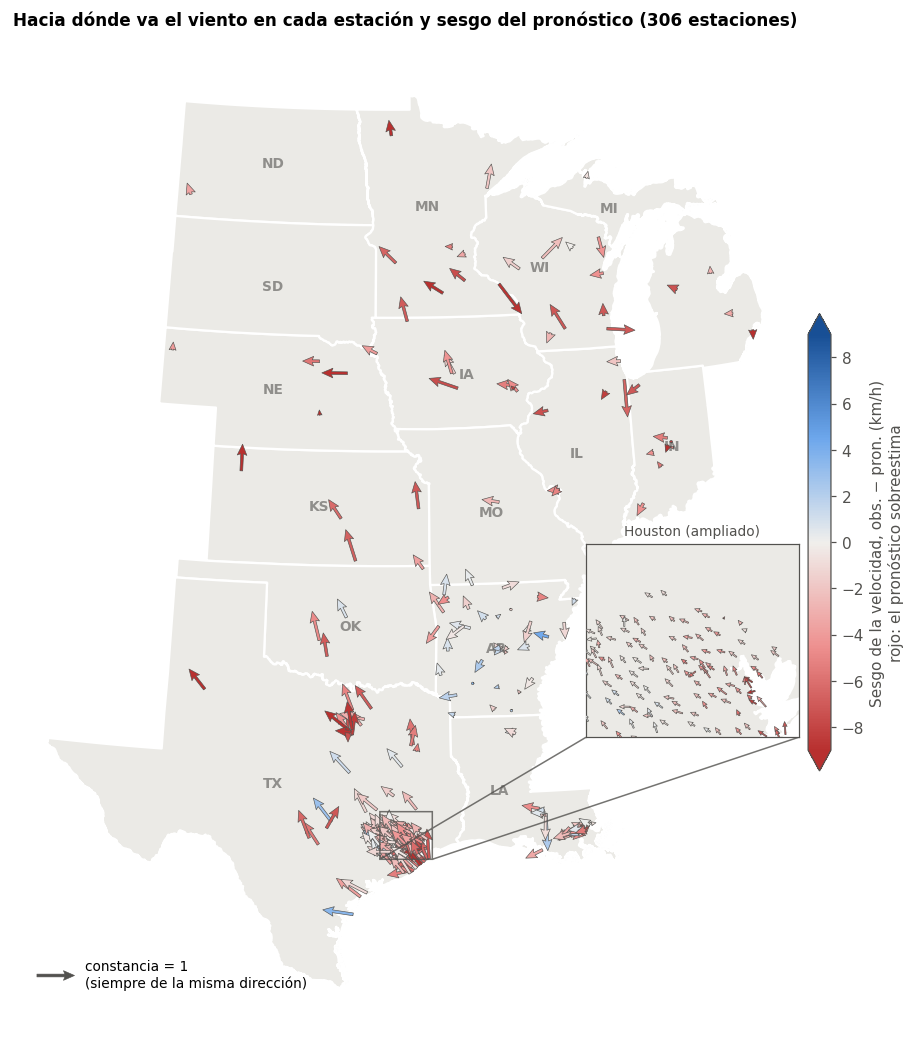

In [21]:
from matplotlib.colors import CenteredNorm
import matplotlib.patheffects as pe

CRS_METRICO = 'EPSG:5070'  # el mismo de analisis_estaciones.ipynb
estados_mapa = gpd.read_file(PROCESSED + 'estados_central.geojson').to_crs(CRS_METRICO)

# Punta de cada flecha: se desplaza el punto hacia donde va el viento en lon/lat y se proyecta,
# así la dirección respeta el norte verdadero aunque la proyección rote los meridianos
lat, lon = viento_estacion['latitud'].values, viento_estacion['longitud'].values
hacia = np.deg2rad(viento_estacion['direccion'].values + 180)
origen = gpd.GeoSeries(gpd.points_from_xy(lon, lat), crs='EPSG:4326').to_crs(CRS_METRICO)
punta = gpd.GeoSeries(gpd.points_from_xy(lon + 0.1 * np.sin(hacia) / np.cos(np.deg2rad(lat)),
                                         lat + 0.1 * np.cos(hacia)), crs='EPSG:4326').to_crs(CRS_METRICO)
dx, dy = punta.x.values - origen.x.values, punta.y.values - origen.y.values
largo = viento_estacion['constancia'].values / np.hypot(dx, dy)
U, V = dx * largo, dy * largo

norma = CenteredNorm(vcenter=0, halfrange=np.ceil(viento_estacion['sesgo_kmh'].abs().quantile(0.95)))
cmap_sesgo = DIVERGENTE.reversed()  # rojo = el pronóstico sobreestima (sesgo negativo)
estilo_flecha = dict(cmap=cmap_sesgo, norm=norma, angles='xy', scale_units='xy', pivot='tail',
                     edgecolor=GRIS_TEXTO, linewidth=0.4, zorder=3)


def dibujar_flechas(ax, escala_km, ancho):
    """Flechas con constancia 1 = escala_km de largo."""
    return ax.quiver(origen.x, origen.y, U, V, viento_estacion['sesgo_kmh'], scale=1 / (escala_km * 1000),
                     width=ancho, headwidth=3.5, headlength=4, headaxislength=3.5, **estilo_flecha)


fig, ax = plt.subplots(figsize=(11, 12))
estados_mapa.plot(ax=ax, color='#ebeae6', edgecolor='white', linewidth=1.5)
for _, fila in estados_mapa.iterrows():
    p = fila.geometry.representative_point()
    ax.annotate(fila['estado'], (p.x, p.y), ha='center', va='center', fontsize=9, color=GRIS_TEXTO,
                fontweight='bold', alpha=0.6, zorder=2)
q = dibujar_flechas(ax, escala_km=110, ancho=0.0035)
ax.quiverkey(q, 0.08, 0.06, 1, 'constancia = 1\n(siempre de la misma dirección)', labelpos='E',
             coordinates='axes', color=GRIS_TEXTO, fontproperties={'size': 9})

# Recuadro ampliado del área de Houston, donde se concentran las estaciones de CENTERPOINT
houston = gpd.GeoSeries(gpd.points_from_xy([-96.25, -94.65], [29.3, 30.55]), crs='EPSG:4326').to_crs(CRS_METRICO)
axins = ax.inset_axes([0.73, 0.29, 0.27, 0.22])  # hueco al este de Arkansas
estados_mapa.plot(ax=axins, color='#ebeae6', edgecolor='white', linewidth=1.5)
dibujar_flechas(axins, escala_km=12, ancho=0.006)
axins.set_xlim(houston.x.min(), houston.x.max())
axins.set_ylim(houston.y.min(), houston.y.max())
axins.set_xticks([]), axins.set_yticks([])
axins.grid(False)
for borde in axins.spines.values():
    borde.set_visible(True), borde.set_edgecolor(GRIS_TEXTO), borde.set_linewidth(0.8)
axins.set_title('Houston (ampliado)', fontsize=9, fontweight='normal', color=GRIS_TEXTO)
ax.indicate_inset_zoom(axins, edgecolor=GRIS_TEXTO, alpha=0.8)

fig.colorbar(q, ax=ax, shrink=0.45, pad=0.01, extend='both',
             label='Sesgo de la velocidad, obs. − pron. (km/h)\nrojo: el pronóstico sobreestima')
ax.set_title(f'Hacia dónde va el viento en cada estación y sesgo del pronóstico ({len(viento_estacion)} estaciones)')
ax.set_axis_off()
figuras['07_mapa_viento'] = fig
plt.show()

Resumen por franja de latitud. Se repite sin APRSWXNET para separar el efecto de la ubicación del de la red (la red de aficionados subestima mucho el viento).

In [22]:
FRANJAS = [25, 31, 37, 43, 50]
ETIQUETAS_FRANJA = ['25–31° (Golfo)', '31–37°', '37–43°', '43–50° (norte)']
red_estacion = redes.set_index('station_id')['red']

for d in (con_dir, pares_viento):
    d['franja'] = pd.cut(d['station_id'].map(coords['latitud']), FRANJAS, labels=ETIQUETAS_FRANJA)
    d['red'] = d['station_id'].map(red_estacion)


def resumen_franjas(dir_, pares):
    """Vector medio, sesgo de la velocidad y % de observaciones por sector, por franja de latitud."""
    tabla = dir_.groupby('franja', observed=True)[['u', 'v', 'obs_windspeed_kmh']].apply(vector_medio)
    tabla['% obs.'] = 100 * tabla['n'] / tabla['n'].sum()
    tabla['sesgo_kmh'] = pares.groupby('franja', observed=True)['error'].mean()
    sector = np.array(sectores)[(((dir_['obs_wind_direction_d'] + 22.5) % 360) // 45).astype(int)]
    return tabla.join(pd.crosstab(dir_['franja'], sector, normalize='index').mul(100)[sectores])


tabla_viento_franja = pd.concat({
    'Todas las redes': resumen_franjas(con_dir, pares_viento),
    'Sin APRSWXNET': resumen_franjas(con_dir[con_dir['red'] != 'APRSWXNET'], pares_viento[pares_viento['red'] != 'APRSWXNET']),
})
tabla_viento_franja['n'] = tabla_viento_franja['n'].astype(int)
tabla_viento_franja = tabla_viento_franja.round({'direccion': 0, 'constancia': 2, 'vel_media_kmh': 1, '% obs.': 1,
                                                 'sesgo_kmh': 2, **{s: 0 for s in sectores}})
tabla_viento_franja

n  direccion  constancia  vel_media_kmh  \
                franja                                                         
Todas las redes 25–31° (Golfo)  105521      127.0        0.48            5.8   
                31–37°           27273      129.0        0.28            6.1   
                37–43°           10384      107.0        0.24            6.1   
                43–50° (norte)    7290      157.0        0.30            7.2   
Sin APRSWXNET   25–31° (Golfo)  104404      126.0        0.49            5.7   
                31–37°           25854      126.0        0.27            6.2   
                37–43°            6506      107.0        0.24            6.9   
                43–50° (norte)    4384      163.0        0.29            8.3   

                                % obs.  sesgo_kmh     N    NE     E    SE  \
                franja                                                      
Todas las redes 25–31° (Golfo)    70.1      -2.65   9.0  13.0  18.0  24.0   
                31–37°            18.1      -1.79  11.0  15.0  14.0  18.0   
                37–43°             6.9      -6.05  14.0  14.0  18.0  15.0   
                43–50° (norte)     4.8      -5.30   6.0  10.0  15.0  19.0   
Sin APRSWXNET   25–31° (Golfo)    74.0      -2.60   9.0  13.0  18.0  24.0   
                31–37°            18.3      -1.15  12.0  15.0  15.0  17.0   
                37–43°             4.6      -4.76  15.0  14.0  19.0  15.0   
                43–50° (norte)     3.1      -3.90   4.0   9.0  13.0  20.0   

                                   S    SO     O    NO  
                franja                                  
Todas las redes 25–31° (Golfo)  19.0   8.0   4.0   5.0  
                31–37°          19.0   9.0   7.0   6.0  
                37–43°          14.0  10.0   8.0   6.0  
                43–50° (norte)  15.0  10.0   8.0  17.0  
Sin APRSWXNET   25–31° (Golfo)  19.0   8.0   4.0   5.0  
                31–37°          18.0   9.0   7.0   7.0  
                37–43°          14.0  10.0   8.0   5.0  
                43–50° (norte)  13.0  10.0  10.0  23.0

## 8. Error del pronóstico por variable

En esta sección el error se define como **pronosticado − observado** (signo opuesto al de las secciones anteriores):
un error positivo indica que el pronóstico **sobreestima** la variable y uno negativo que la subestima.
Para cada variable se usan todos los pares completos y se informan:

- **Sesgo**: media del error (error sistemático).
- **MAE**: media del error absoluto (tamaño típico del error, en las unidades de la variable).
- **RMSE**: raíz del error cuadrático medio. Penaliza más los errores grandes, así que RMSE ≫ MAE indica colas pesadas.
- **n**: cantidad de pares observación–pronóstico.

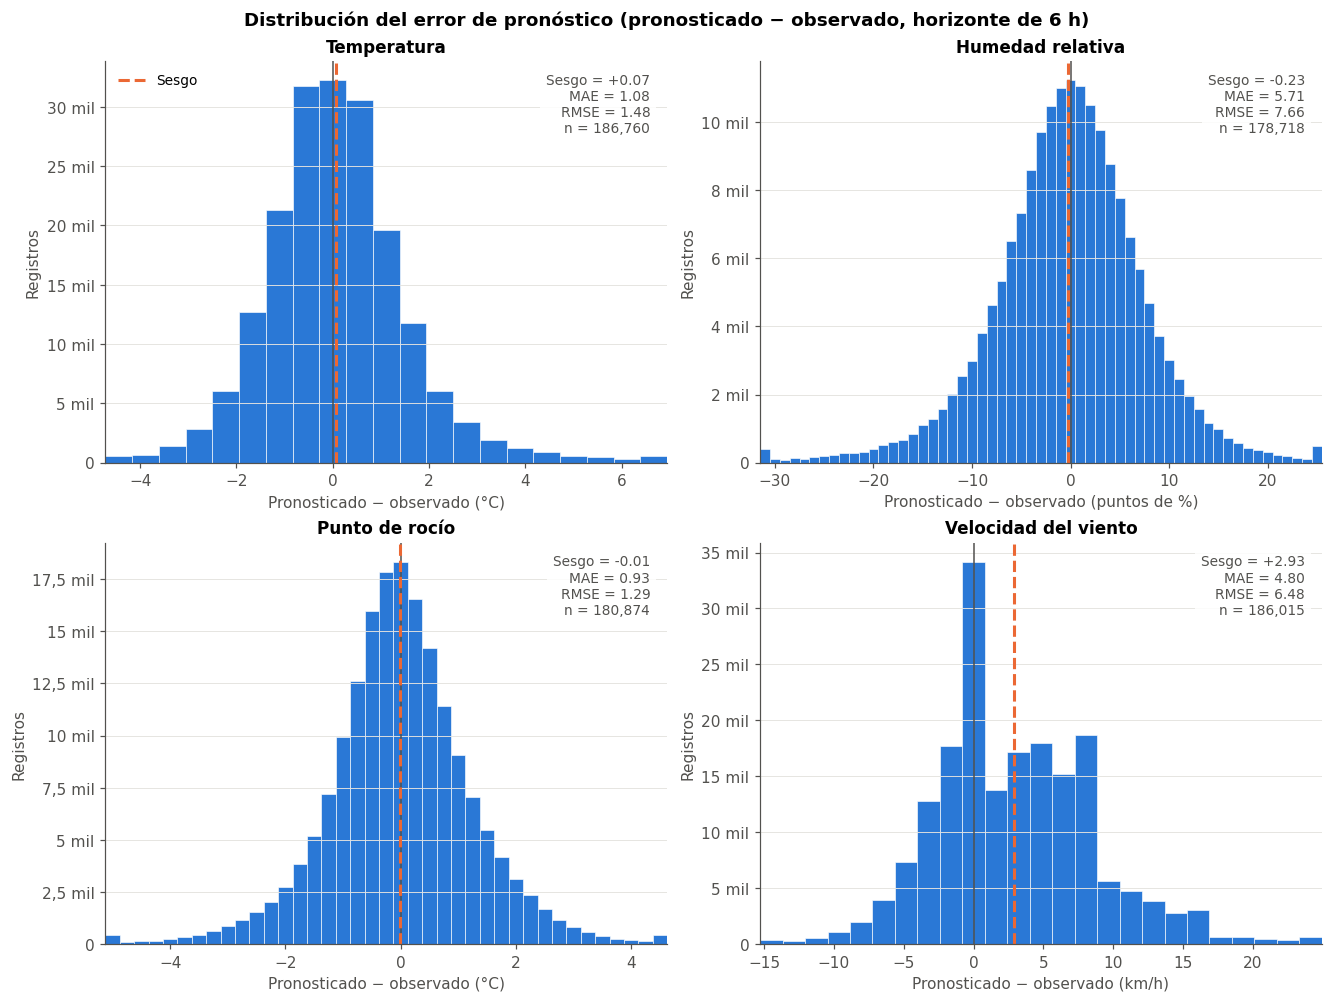

,n,Sesgo,MAE,RMSE
Temperatura,186760,0.07,1.08,1.48
Humedad relativa,178718,-0.23,5.71,7.66
Punto de rocío,180874,-0.01,0.93,1.29
Velocidad del viento,186015,2.93,4.80,6.48


In [23]:
# Ancho de clase del histograma: en temperatura y viento coincide con el paso del pronóstico (1 °F y 1 mph),
# porque los errores se agrupan en sus múltiplos y otro ancho genera picos falsos
ERRORES = [
    ('Temperatura', '°C', 'fcst_temp_c', 'obs_temp_c', 5 / 9),
    ('Humedad relativa', 'puntos de %', 'fcst_rh_pct', 'obs_rh_pct', 1),
    ('Punto de rocío', '°C', 'fcst_dewpoint_c', 'obs_dewpoint_c', 0.25),
    ('Velocidad del viento', 'km/h', 'fcst_windspeed_kmh', 'obs_windspeed_kmh', 1.609344),
]
for nombre, _, pron, obs, _ in ERRORES:
    mp[f'error_{nombre}'] = mp[pron] - mp[obs]  # pronosticado − observado


def metricas_error(e):
    e = e.dropna()
    return pd.Series({'n': len(e), 'Sesgo': e.mean(), 'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean())})


fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
filas = {}
for ax, (nombre, unidad, _, _, paso) in zip(axes.flat, ERRORES):
    e = mp[f'error_{nombre}'].dropna()
    m = filas[nombre] = metricas_error(e)
    # El eje cubre el 99,5 % central para que las colas no aplasten el histograma (las métricas usan todos los datos).
    # Las clases se centran en múltiplos del paso, así el error nulo cae en el medio de una barra
    k_min, k_max = np.floor(e.quantile(0.0025) / paso), np.ceil(e.quantile(0.9975) / paso)
    bins = (np.arange(k_min, k_max + 2) - 0.5) * paso
    ax.hist(e.clip(bins[0], bins[-1]), bins=bins, color=AZUL, edgecolor='white', linewidth=0.4)
    ax.axvline(0, color=GRIS_TEXTO, lw=1)
    ax.axvline(m['Sesgo'], color=NARANJA, lw=2, ls='--', label='Sesgo')
    ax.text(0.97, 0.97, f'Sesgo = {m["Sesgo"]:+.2f}\nMAE = {m["MAE"]:.2f}\nRMSE = {m["RMSE"]:.2f}\nn = {m["n"]:,.0f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color=GRIS_TEXTO,
            bbox=dict(fc='white', ec='none', alpha=0.85))
    ax.set(title=nombre, xlabel=f'Pronosticado − observado ({unidad})', ylabel='Registros', xlim=(bins[0], bins[-1]))
    ax.yaxis.set_major_formatter(lambda v, _: f'{v / 1000:g} mil'.replace('.', ',') if v else '0')
    ax.grid(axis='x', visible=False)
axes[0, 0].legend(loc='upper left', frameon=False, fontsize=9)
fig.suptitle('Distribución del error de pronóstico (pronosticado − observado, horizonte de 6 h)', fontweight='bold')
figuras['08_distribucion_error'] = fig
plt.show()

tabla_error = pd.DataFrame(filas).T
tabla_error['n'] = tabla_error['n'].astype(int)
tabla_error.round(2)

Los histogramas muestran el 99,5 % central de cada distribución (los valores más extremos se acumulan en las barras de los bordes);
las métricas se calculan con todos los pares. La línea gris marca el error nulo y la naranja el sesgo.
El pronóstico de temperatura viene en °F enteros y el de viento en mph enteras, así que sus errores se agrupan en múltiplos
de 5/9 °C y de 1,609 km/h: el ancho de las barras coincide con ese paso para no generar picos artificiales.

### Variación del error según la hora del día

Para cada variable y hora local se grafica el **sesgo** (media del error, con el rango intercuartílico P25–P75 como banda)
y el **MAE**. El sesgo indica en qué horas el pronóstico se corre sistemáticamente hacia arriba o hacia abajo; el MAE, en qué
horas falla más, sin importar el signo.

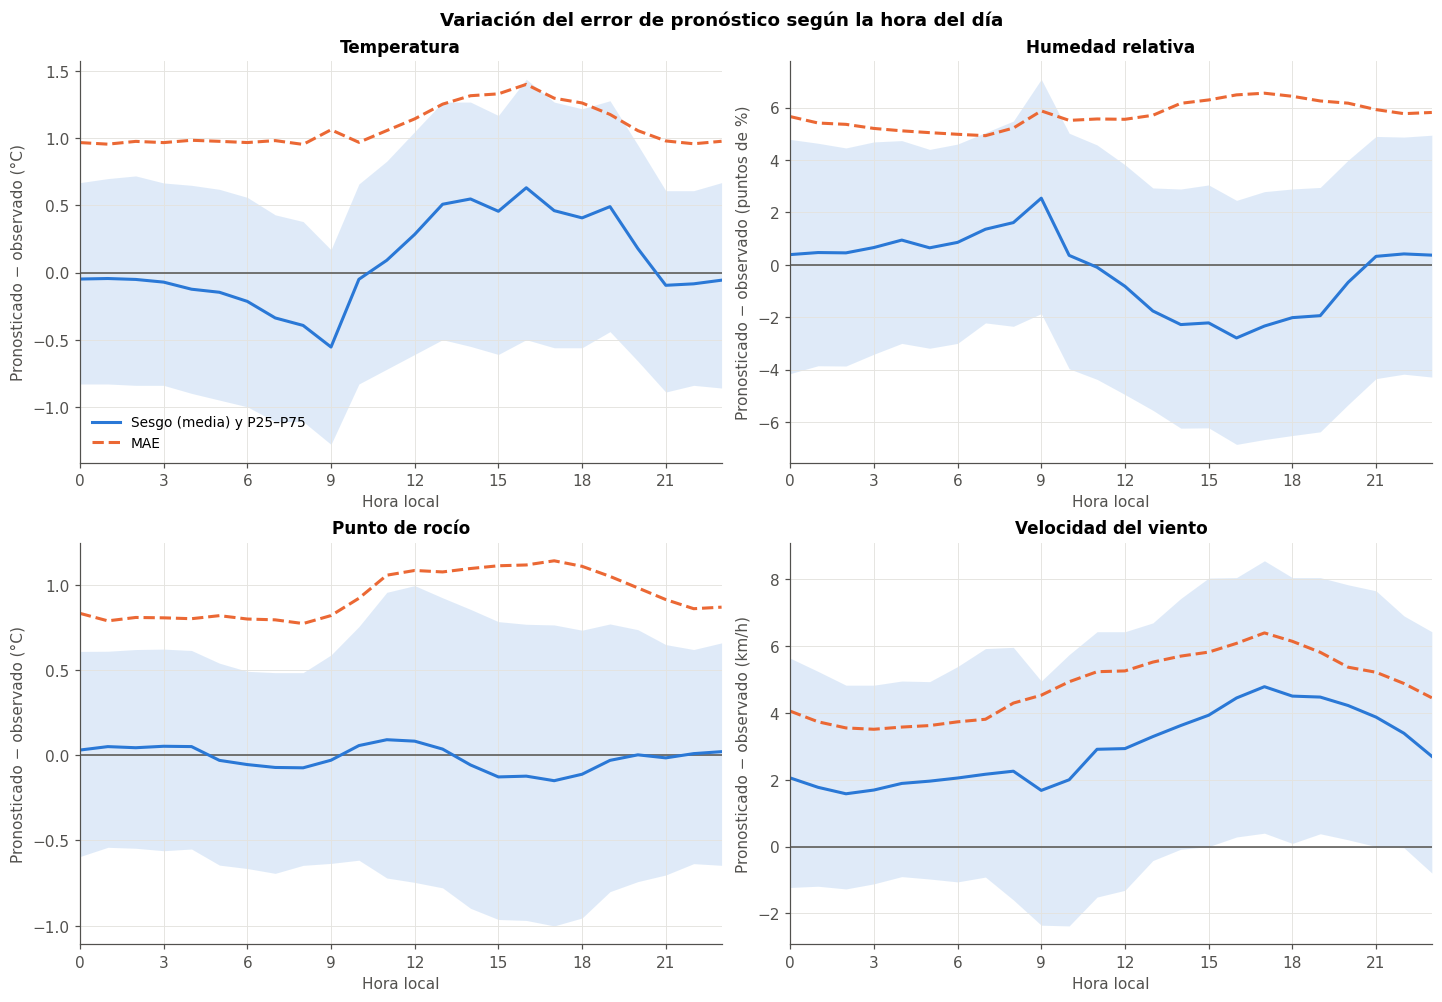

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for ax, (nombre, unidad, *_) in zip(axes.flat, ERRORES):
    col = f'error_{nombre}'
    ax.axhline(0, color=GRIS_TEXTO, lw=1)
    banda_por_hora(ax, mp, col, AZUL, 'Sesgo (media) y P25–P75')
    mae_hora = mp[col].abs().groupby(mp['hora_local']).mean()
    ax.plot(mae_hora.index, mae_hora.values, color=NARANJA, lw=2, ls='--', label='MAE')
    ax.set(title=nombre, xlabel='Hora local', ylabel=f'Pronosticado − observado ({unidad})',
           xticks=range(0, 24, 3), xlim=(0, 23))
axes[0, 0].legend(frameon=False, loc='lower left', fontsize=9)
fig.suptitle('Variación del error de pronóstico según la hora del día', fontweight='bold')
figuras['09_error_por_hora'] = fig
plt.show()

Horas en que el sesgo y el MAE alcanzan sus extremos, para cada variable:

In [25]:
filas = {}
for nombre, *_ in ERRORES:
    g = mp.groupby('hora_local')[f'error_{nombre}']
    sesgo, mae = g.mean(), g.apply(lambda e: e.abs().mean())
    filas[nombre] = {
        'Sesgo mín.': sesgo.min(), 'hora sesgo mín.': sesgo.idxmin(),
        'Sesgo máx.': sesgo.max(), 'hora sesgo máx.': sesgo.idxmax(),
        'MAE mín.': mae.min(), 'hora MAE mín.': mae.idxmin(),
        'MAE máx.': mae.max(), 'hora MAE máx.': mae.idxmax(),
    }
tabla_error_hora = pd.DataFrame(filas).T
horas = [c for c in tabla_error_hora if c.startswith('hora')]
tabla_error_hora[horas] = tabla_error_hora[horas].astype(int)
tabla_error_hora.round(2)

,Sesgo mín.,hora sesgo mín.,Sesgo máx.,hora sesgo máx.,MAE mín.,hora MAE mín.,MAE máx.,hora MAE máx.
Temperatura,-0.55,9,0.63,16,0.95,8,1.40,16
Humedad relativa,-2.79,16,2.54,9,4.93,7,6.55,17
Punto de rocío,-0.15,17,0.09,11,0.77,8,1.14,17
Velocidad del viento,1.58,2,4.79,17,3.51,3,6.39,17


### Sesgo según el valor observado

Se agrupan los pares por el valor **observado** de cada variable y en cada clase se calcula el sesgo (media de pronosticado − observado)
y el rango intercuartílico del error. Debajo de cada panel se muestra cuántos pares hay en cada clase. Sólo se grafican las clases con
al menos 200 pares. Las clases tienen el ancho de 1 °F en temperatura y punto de rocío, de 2 puntos en HR y de 1 mph en viento,
para respetar la resolución con la que se reportan los datos.

Al condicionar por la observación, cualquier pronóstico imperfecto muestra una pendiente negativa (regresión a la media): si se elige
un momento en que hizo mucho calor, lo más probable es que el pronóstico se haya quedado corto, aunque en promedio no tenga sesgo.
Por eso la pendiente indica que el pronóstico **no alcanza los extremos** observados, y lo que distingue a cada variable es cuán
pronunciada es y si la curva cruza el cero en el centro de la distribución o desplazada hacia un lado.

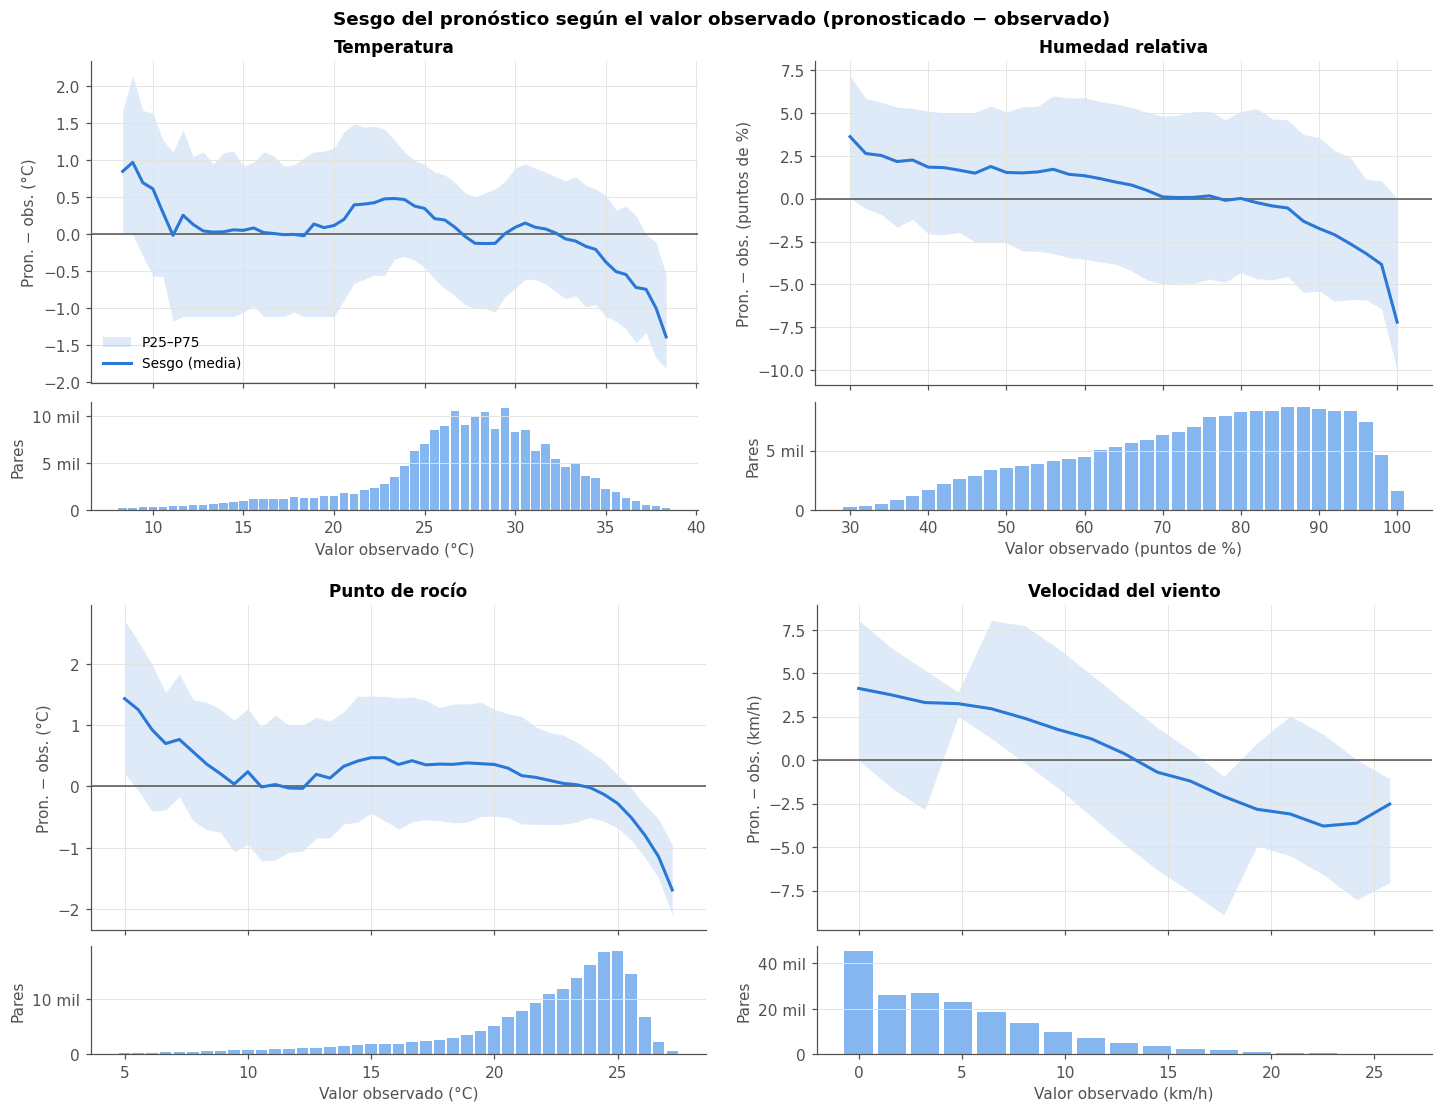

In [26]:
ANCHO_CLASE_OBS = {'Temperatura': 5 / 9, 'Humedad relativa': 2, 'Punto de rocío': 5 / 9, 'Velocidad del viento': 1.609344}


def sesgo_por_valor(datos, error, obs, ancho, n_min=200):
    """Sesgo, P25–P75 y n del error por clase del valor observado (clases centradas en múltiplos del ancho)."""
    d = datos[[obs, error]].dropna()
    g = d.groupby((d[obs] / ancho).round() * ancho)[error]
    tabla = g.agg(n='count', sesgo='mean').join(g.quantile([0.25, 0.75]).unstack())
    return tabla[tabla['n'] >= n_min]


fig = plt.figure(figsize=(13, 10), constrained_layout=True)
for sf, (nombre, unidad, _, obs, _) in zip(fig.subfigures(2, 2, wspace=0.03, hspace=0.03).flat, ERRORES):
    ax, ax_n = sf.subplots(2, 1, sharex=True, height_ratios=[3, 1])
    ancho = ANCHO_CLASE_OBS[nombre]
    t = sesgo_por_valor(mp, f'error_{nombre}', obs, ancho)
    ax.axhline(0, color=GRIS_TEXTO, lw=1)
    ax.fill_between(t.index, t[0.25], t[0.75], color=AZUL, alpha=0.15, linewidth=0, label='P25–P75')
    ax.plot(t.index, t['sesgo'], color=AZUL, lw=2, label='Sesgo (media)')
    ax.set(title=nombre, ylabel=f'Pron. − obs. ({unidad})')
    ax_n.bar(t.index, t['n'], width=ancho * 0.85, color='#86b6ef', linewidth=0)
    ax_n.set(xlabel=f'Valor observado ({unidad})', ylabel='Pares')
    ax_n.yaxis.set_major_formatter(lambda v, _: f'{v / 1000:g} mil'.replace('.', ',') if v else '0')
    ax_n.grid(axis='x', visible=False)
    if nombre == ERRORES[0][0]:
        ax.legend(frameon=False, loc='lower left', fontsize=9)
fig.suptitle('Sesgo del pronóstico según el valor observado (pronosticado − observado)', fontweight='bold')
figuras['10_sesgo_segun_observado'] = fig
plt.show()

Sesgo en las colas y en el centro de la distribución observada de cada variable (P10 y P90 del valor observado).
En el viento, P10 = 0 porque las calmas superan el 10 % de las observaciones, así que la primera columna corresponde a las calmas.

In [27]:
filas = {}
for nombre, _, _, obs, _ in ERRORES:
    d = mp[[obs, f'error_{nombre}']].dropna()
    p10, p90 = d[obs].quantile([0.1, 0.9])
    rango = pd.cut(d[obs], [-np.inf, p10, p90, np.inf], labels=['≤ P10', 'P10–P90', '> P90'])
    sesgo = d.groupby(rango, observed=False)[f'error_{nombre}'].mean()
    filas[nombre] = {'P10 obs.': p10, 'P90 obs.': p90, **{f'Sesgo obs. {r}': s for r, s in sesgo.items()}}
tabla_error_obs = pd.DataFrame(filas).T
tabla_error_obs.round(2)

,P10 obs.,P90 obs.,Sesgo obs. ≤ P10,Sesgo obs. P10–P90,Sesgo obs. > P90
Temperatura,20.39,33.14,0.19,0.11,-0.34
Humedad relativa,50.02,93.97,1.87,-0.07,-3.63
Punto de rocío,15.87,25.48,0.36,0.04,-0.81
Velocidad del viento,0.00,11.27,4.37,3.06,-0.89


## 9. Conclusiones

**Calidad de los datos**

- Los negativos de tres columnas venían como texto (`'-5.56`) y hubo que convertirlos. Además se descartaron 44 temperaturas,
  43 puntos de rocío y 6 vientos físicamente imposibles.
- El 34,7 % de las filas no tenía ninguna observación. La mayoría venía de 129 estaciones hidrológicas sin sensores meteorológicos
  (HADS, AUSTIN, MIDCoEMO, HCFCD), que se excluyeron: quedan 345 estaciones y 217.297 filas.
- Tras el filtro, el 11,6 % de las filas sigue sin observación, concentrado en estaciones intermitentes de la red APRSWXNET.
  Cada variable observada tiene dato en el 82–86 % de las filas (73 % la sensación térmica, que sólo se informa con calor).
  Los pronósticos están completos. Cada gráfico usa los pares disponibles.

**Observado vs. pronosticado (6 h)**

- Temperatura (r = 0,96; MAE ≈ 1,1 °C) y punto de rocío (r = 0,95; MAE ≈ 0,9 °C) se pronostican muy bien y casi sin sesgo.
- La humedad relativa también acompaña bien (r = 0,89; MAE ≈ 5,7 puntos). Se nota la saturación en 100 %.
- El viento es la variable peor pronosticada (r = 0,52). El pronóstico **sobreestima** la velocidad en ≈ 2,9 km/h en promedio,
  más por la tarde (≈ 4,8 km/h a las 17 h) que de madrugada (≈ 1,6 km/h a las 2 h). Muchas estaciones reportan calma (18,6 % de las
  observaciones de viento) mientras el pronóstico indica viento leve. Además, el pronóstico está
  cuantizado en millas por hora (5 mph = 8,05 km/h), lo que genera las franjas verticales.
- No es un problema de unidades: se verificó que observación y pronóstico están en km/h. La diferencia depende sobre todo de dónde
  está el sensor. Las estaciones RAWS, en campo abierto y a altura estándar, alcanzan r = 0,80, mientras que las de aficionados de
  APRSWXNET (47 % de calmas) quedan en r = 0,35 con un sesgo de −7,2 km/h. Sin APRSWXNET, el r global sube de 0,52 a 0,56.

**Relaciones entre variables**

- Temperatura y humedad relativa tienen una relación negativa fuerte (ρ = −0,71): a mayor temperatura, menor HR. Es el ciclo diario
  el que las mueve en direcciones opuestas.
- El punto de rocío queda siempre por debajo de la temperatura (cota `y = x`). Sube con ella hasta ≈ 25 °C y luego se estabiliza,
  por eso Spearman (0,34) es mucho menor que Pearson (0,63).
- La sensación térmica coincide con la temperatura por debajo de ≈ 26 °C y se separa hacia arriba con calor húmedo
  (hasta 10–15 °C más). En el dataset sólo aparece a partir de ≈ 21 °C.
- El viento se asocia débilmente con menor humedad (ρ = −0,43) y mayor temperatura (ρ = 0,39): sopla más fuerte por la tarde.
- La probabilidad de precipitación se relaciona sobre todo con la humedad del aire (ρ = 0,37 con el punto de rocío observado y 0,39 con el pronosticado).

**Error del pronóstico de temperatura**

- Tiene un patrón diario: a primera hora de la mañana el pronóstico es algo más frío que lo observado (+0,5 °C a las 9 h),
  y por la tarde algo más cálido (−0,5 °C entre las 13 y las 19 h).
- Con probabilidad de precipitación intermedia (41–60 %) el error aumenta (MAE 1,86 °C) y el pronóstico sobreestima la temperatura
  (sesgo −0,96 °C). Cuando la lluvia es incierta, el enfriamiento que produce es difícil de anticipar.

**Viento**

- Predominan los vientos del **sureste, sur y este** (≈ 58 % de las observaciones sin calma), que son también los más intensos
  (P90 ≈ 13 km/h). Es coherente con el flujo de aire húmedo desde el Golfo de México. Los del norte y el noroeste son menos
  frecuentes y más débiles.
- Esa rosa refleja sobre todo la franja del Golfo, que aporta el 70 % de las observaciones. El mapa de vectores muestra que el flujo
  del SE es estable en el sur (constancia 0,48) y se vuelve más variable hacia el norte (0,24–0,30). Por encima de 43° aparece el
  viento del noroeste (23 % de las observaciones sin APRSWXNET), probablemente por el paso de frentes fríos.
- El pronóstico sobreestima más la velocidad por encima de 37° (sesgo de −3,9 a −4,8 km/h sin APRSWXNET) que en el Golfo (−2,6 km/h).
  La diferencia se mantiene al quitar la red de aficionados, así que no se explica sólo por la red, aunque se apoya en pocas
  estaciones (menos del 8 % de las observaciones). Arkansas, con la red ARDOT, es la única zona prácticamente sin sesgo.

**Error de pronóstico por variable (pronosticado − observado)**

- Temperatura y punto de rocío tienen errores simétricos y centrados en cero (sesgo +0,07 °C y −0,01 °C; MAE 1,08 °C y 0,93 °C;
  RMSE 1,48 °C y 1,29 °C). La humedad relativa tampoco tiene sesgo global (−0,23 puntos), pero su error típico es de 5,7 puntos
  (RMSE 7,7), con una cola más larga del lado negativo.
- El viento es la única variable con sesgo claro: el pronóstico lo **sobreestima** en 2,9 km/h en promedio (MAE 4,8; RMSE 6,5).
  La distribución es asimétrica, con un pico en cero y una cola hacia los valores positivos.
- Por hora del día, el sesgo de temperatura cambia de signo: el pronóstico es más frío que lo observado a la mañana (−0,55 °C a las 9 h)
  y más cálido por la tarde (+0,63 °C a las 16 h), cuando también es mayor el MAE (1,40 °C). La humedad relativa muestra el patrón
  opuesto (+2,5 puntos a las 9 h y −2,8 a las 16 h), mientras que el sesgo del punto de rocío se mantiene por debajo de 0,15 °C a toda hora.
  El error diario de la HR se explica entonces por el de la temperatura y no por la cantidad de vapor.
- El viento se sobreestima a toda hora, pero el error crece por la tarde: el sesgo va de +1,6 km/h a las 2 h a +4,8 km/h a las 17 h,
  y el MAE de 3,5 a 6,4 km/h. En las cuatro variables el MAE máximo cae entre las 16 y las 17 h.
- Según el valor observado, las cuatro variables muestran que el pronóstico **no alcanza los extremos**: sobreestima los valores bajos
  y subestima los altos. Parte de esa pendiente es esperable en cualquier pronóstico imperfecto (regresión a la media), pero su tamaño
  cambia mucho entre variables:
  - **Temperatura**: es la más pareja. El sesgo se mantiene por debajo de ±0,5 °C entre 12 y 34 °C y sólo crece en los extremos poco
    frecuentes (≈ +1 °C con menos de 10 °C, −1,4 °C cerca de 38 °C).
  - **Humedad relativa**: tiene la pendiente más marcada. Pasa de +3,6 puntos con 30 % de HR a −3,6 por encima de 94 % y a ≈ −7
    en saturación (100 %). El pronóstico rara vez llega a saturación, que se observa con niebla o rocío nocturno.
  - **Punto de rocío**: casi no tiene sesgo en el rango central, pero subestima el aire más húmedo (−0,8 °C por encima de 25,5 °C y
    −1,7 °C cerca de 27 °C).
  - **Velocidad del viento**: sobreestima hasta ≈ 13 km/h (+4,4 km/h con calma) y subestima por encima (≈ −3,8 km/h cerca de 22 km/h).
    Como las calmas y los vientos leves son los más frecuentes, dominan el sesgo global positivo.

## 10. Exportación de los gráficos

In [28]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
tabla_obs_pron.to_csv(OUT + 'tabla_observado_vs_pronosticado.csv')
tabla_viento_franja.to_csv(OUT + 'tabla_viento_por_franja.csv')
tabla_error.to_csv(OUT + 'tabla_error_pronostico.csv')
tabla_error_hora.to_csv(OUT + 'tabla_error_por_hora.csv')
tabla_error_obs.to_csv(OUT + 'tabla_sesgo_segun_observado.csv')
print(f'Guardados {len(figuras)} gráficos y 5 tablas en {OUT}')

Guardados 10 gráficos y 5 tablas en ../data/out/bivariadas/
